# Integrated Gradients Under Attack: A Second Explanation Method for the Same Question

`01_gradcam_under_attack.ipynb` visualizes model attention with Grad-CAM, which reads a single late convolutional layer and is therefore always coarse, roughly the resolution of that layer's feature map rather than the input image. Integrated Gradients (Sundararajan et al., 2017, "Axiomatic Attribution for Deep Networks") instead attributes the prediction directly to individual input pixels, by accumulating gradients along a straight path from a neutral baseline image to the actual input, which makes it a genuinely different, finer-grained way of answering the same question this folder is built around: where is the model actually looking, and does an attack change that.

The method satisfies two axioms Grad-CAM does not: sensitivity (a feature that changes the prediction must receive non-zero attribution) and implementation invariance (two functionally identical networks get identical attributions), at the cost of needing many forward and backward passes per image instead of one. This notebook runs the same before/after-PGD comparison as `01_gradcam_under_attack.ipynb`, on the same two sample images and the same three CNNs, so the two explanation methods can be read side by side.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from tensorflow.keras.applications import EfficientNetB0, InceptionV3, MobileNetV2
from tensorflow.keras.applications.efficientnet import preprocess_input as preprocess_eff, decode_predictions as decode_eff
from tensorflow.keras.applications.inception_v3 import preprocess_input as preprocess_inc, decode_predictions as decode_inc
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as preprocess_mob, decode_predictions as decode_mob

### Setup
Same `models_dict` / `images_dict` convention as `attacks/*.ipynb` and `01_gradcam_under_attack.ipynb`. The baseline for Integrated Gradients is a black image in each model's own input space, `clip_min` broadcast over the full image, rather than a literal zero tensor, since a raw zero does not correspond to black once a model's preprocessing has shifted its input range (MobileNetV2 and InceptionV3 map black to -1, not 0).

In [2]:
def denormalize_eff(img):
    img = tf.clip_by_value(img, 0, 255)
    return img.numpy().squeeze().astype("uint8")

def denormalize_neg1_1(img):
    img = (img + 1.0) / 2.0
    img = img * 255.0
    img = tf.clip_by_value(img, 0, 255)
    return img.numpy().squeeze().astype("uint8")

models_dict = {
    'MobileNetV2': {
        'model': MobileNetV2(weights='imagenet'),
        'target_size': (224, 224), 'preprocess_fn': preprocess_mob, 'decode_fn': decode_mob,
        'denormalize_fn': denormalize_neg1_1, 'clip_min': -1.0, 'clip_max': 1.0,
    },
    'EfficientNetB0': {
        'model': EfficientNetB0(weights='imagenet'),
        'target_size': (224, 224), 'preprocess_fn': preprocess_eff, 'decode_fn': decode_eff,
        'denormalize_fn': denormalize_eff, 'clip_min': 0.0, 'clip_max': 255.0,
    },
    'InceptionV3': {
        'model': InceptionV3(weights='imagenet'),
        'target_size': (299, 299), 'preprocess_fn': preprocess_inc, 'decode_fn': decode_inc,
        'denormalize_fn': denormalize_neg1_1, 'clip_min': -1.0, 'clip_max': 1.0,
    },
}

for config in models_dict.values():
    config['model'].trainable = False

images_dict = {
    'Dog': '../images/dog.png',
    'Lion': '../images/lion.png',
}

In [3]:
def load_and_preprocess_image(img_path, target_size, preprocess_fn):
    img_raw = tf.io.read_file(img_path)
    img = tf.image.decode_image(img_raw, channels=3)
    img = tf.cast(img, tf.float32)
    img = tf.image.resize(img, target_size)
    img = preprocess_fn(img)
    return tf.expand_dims(img, axis=0)

def get_imagenet_class_index(prob):
    return int(tf.argmax(prob, axis=-1).numpy()[0])

### Integrated Gradients and the Attack
`fgsm_attack`/`pgd_attack` are the same implementations used throughout the repo. `integrated_gradients` interpolates `STEPS` images between the baseline and the actual input, runs all of them through the model in a single batch, and integrates the resulting gradients with the trapezoidal rule, exactly as in the original paper.

In [4]:
loss_object = tf.keras.losses.CategoricalCrossentropy()

def fgsm_attack(img, label, epsilon, model, clip_min, clip_max):
    with tf.GradientTape() as tape:
        tape.watch(img)
        pred = model(img, training=False)
        loss = loss_object(label, pred)
    grad = tape.gradient(loss, img)
    return tf.clip_by_value(img + epsilon * tf.sign(grad), clip_min, clip_max)

def pgd_attack(img, label, epsilon, model, clip_min, clip_max, iters=10):
    alpha = epsilon / (iters / 2.0)
    adv_img = tf.identity(img)
    for _ in range(iters):
        with tf.GradientTape() as tape:
            tape.watch(adv_img)
            pred = model(adv_img, training=False)
            loss = loss_object(label, pred)
        grad = tape.gradient(loss, adv_img)
        adv_img = adv_img + alpha * tf.sign(grad)
        perturbation = tf.clip_by_value(adv_img - img, -epsilon, epsilon)
        adv_img = tf.clip_by_value(img + perturbation, clip_min, clip_max)
    return adv_img

STEPS = 30  # interpolation steps between baseline and input; 30-50 is the range the original paper finds sufficient for convergence

def integrated_gradients(img, model, class_idx, clip_min, steps=STEPS):
    """Integrated Gradients (Sundararajan et al., 2017) attribution map for `class_idx`, at full input resolution."""
    baseline = tf.ones_like(img) * clip_min  # a black image in this model's own input space
    alphas = tf.reshape(tf.linspace(0.0, 1.0, steps + 1), (steps + 1, 1, 1, 1))
    interpolated = baseline + alphas * (img - baseline)  # (steps+1, H, W, C)

    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        preds = model(interpolated, training=False)
        scores = preds[:, class_idx]
    grads = tape.gradient(scores, interpolated)

    avg_grads = (grads[:-1] + grads[1:]) / 2.0  # trapezoidal rule
    avg_grads = tf.reduce_mean(avg_grads, axis=0)

    attribution = (img[0] - baseline[0]) * avg_grads
    attribution = tf.reduce_sum(tf.abs(attribution), axis=-1)  # collapse channels into one saliency map
    attribution = attribution / (tf.reduce_max(attribution) + 1e-8)
    return attribution.numpy()

def overlay_heatmap(base_image_uint8, heatmap, alpha=0.4):
    """Blends an attribution map (jet colormap) onto a denormalized uint8 RGB image."""
    heatmap_colored = cm.jet(heatmap)[..., :3] * 255.0
    overlay = (1 - alpha) * base_image_uint8.astype(np.float32) + alpha * heatmap_colored
    return np.clip(overlay, 0, 255).astype(np.uint8)

### Evaluation Loop
For each model and image: Integrated Gradients on the clean prediction, generate a PGD adversarial example ($\varepsilon = 0.05$, identical to `01_gradcam_under_attack.ipynb`), then Integrated Gradients again for the same original class on the now-misclassified adversarial image. Because this map is at full input resolution rather than a coarse conv layer's, it is a useful cross-check on Grad-CAM's story: a genuinely hijacked decision should show up as scattered, high-frequency attribution moving away from the object in both methods, not just the coarser one.


INTEGRATED GRADIENTS UNDER ATTACK - MODEL: MobileNetV2


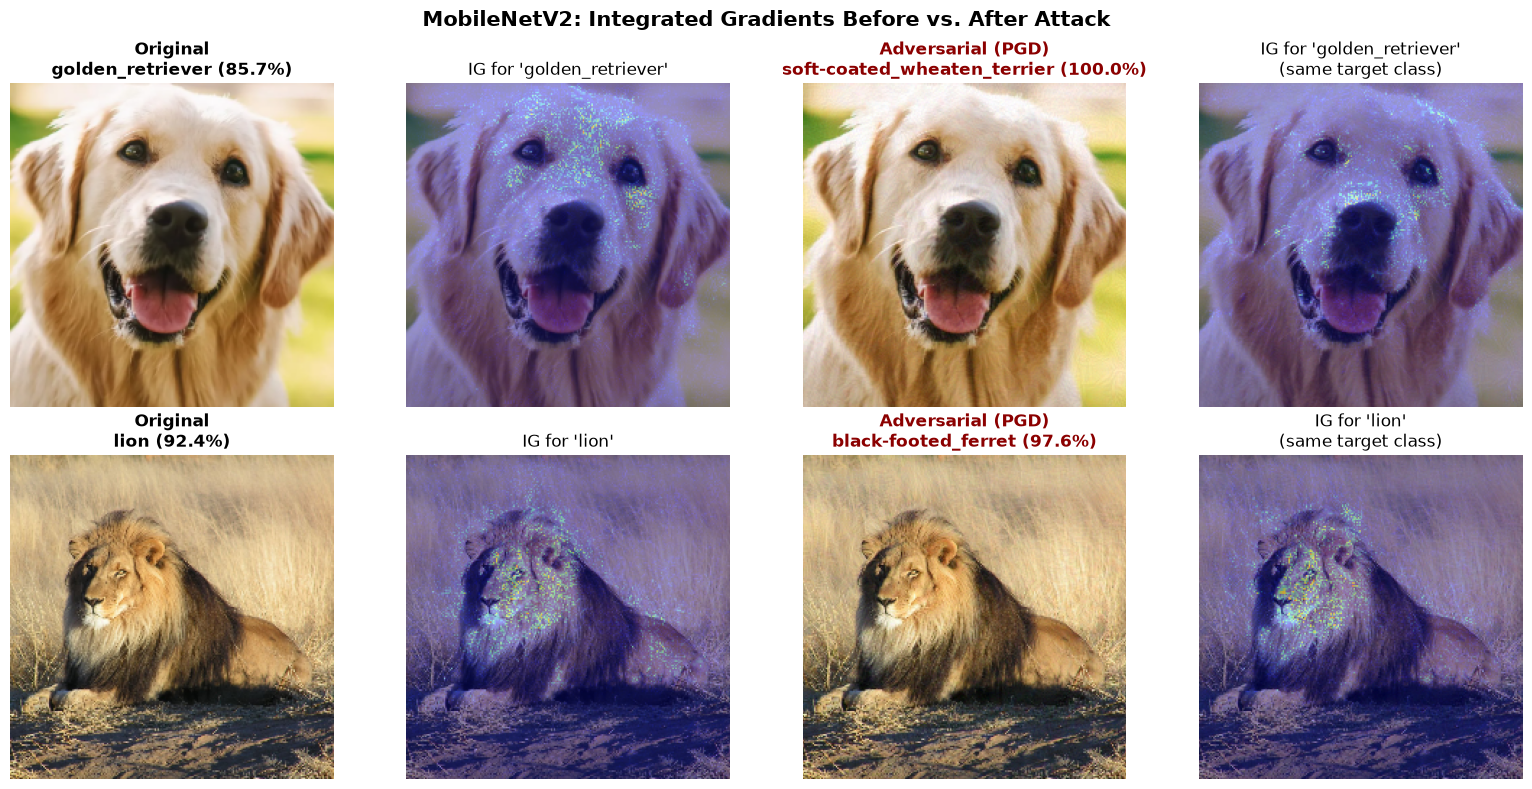


INTEGRATED GRADIENTS UNDER ATTACK - MODEL: EfficientNetB0


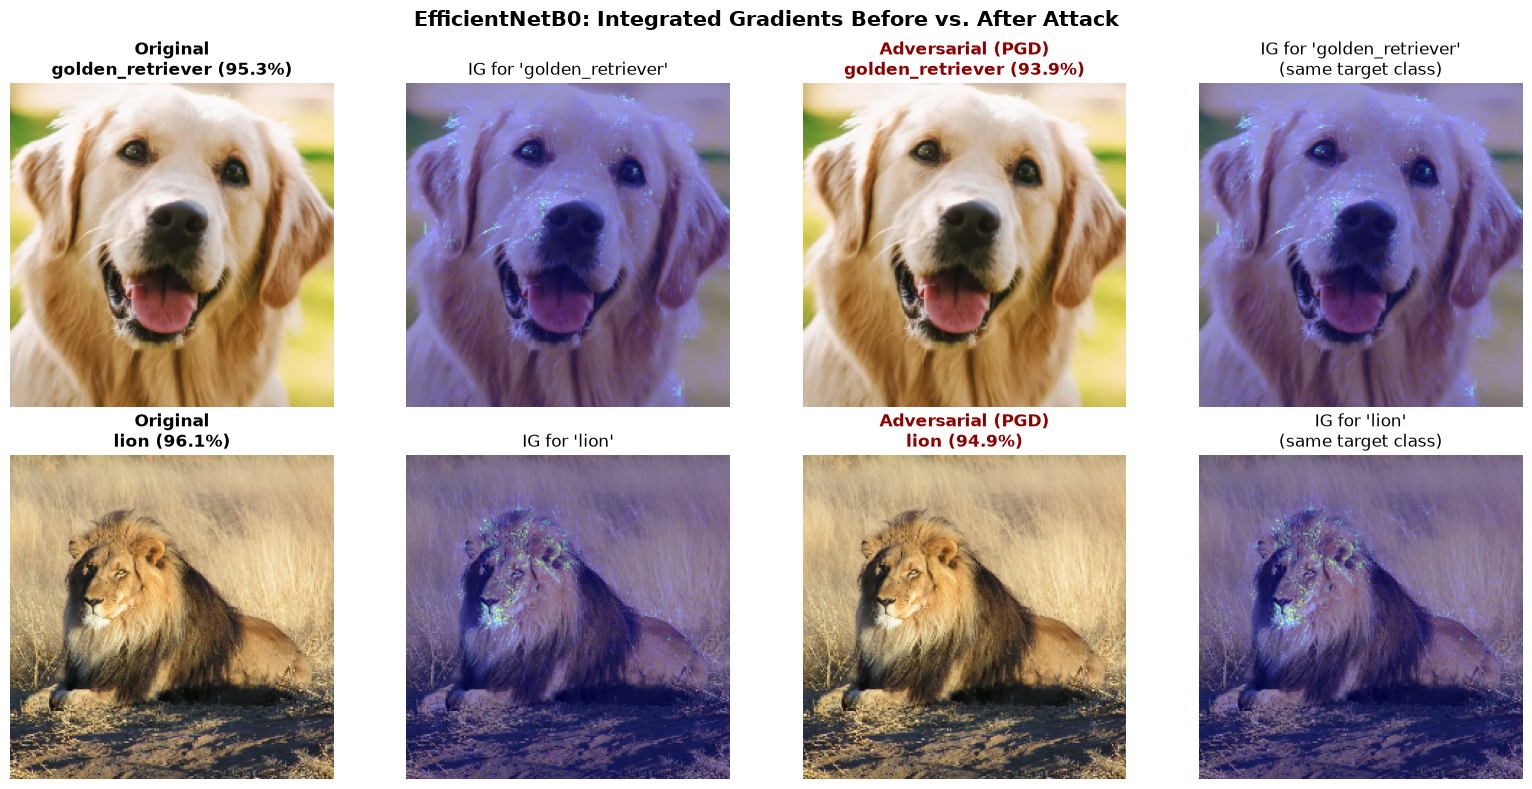


INTEGRATED GRADIENTS UNDER ATTACK - MODEL: InceptionV3


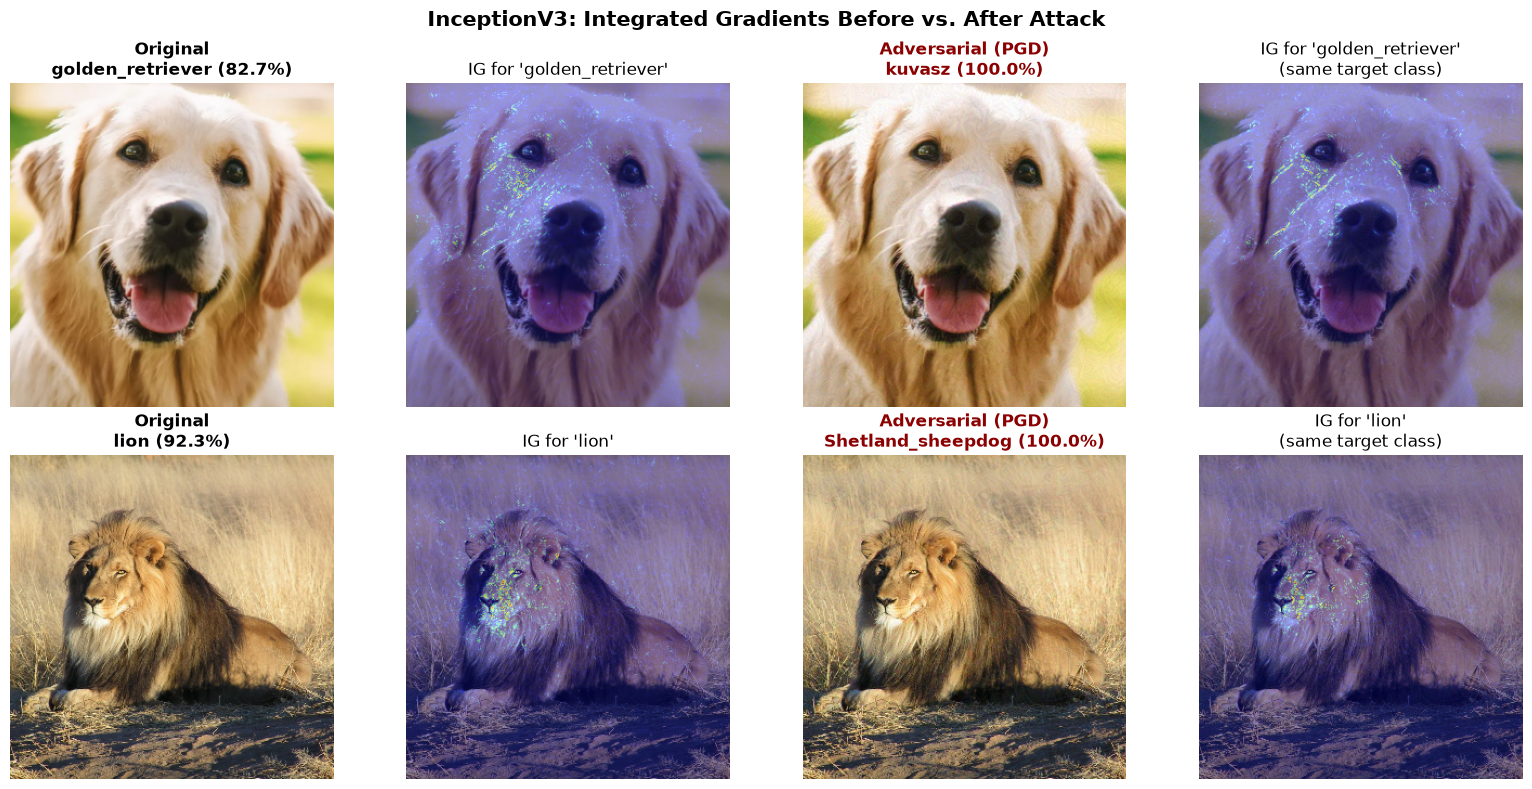

In [5]:
BASE_EPSILON = 0.05

for model_name, m_config in models_dict.items():
    print(f"\n{'='*80}\nINTEGRATED GRADIENTS UNDER ATTACK - MODEL: {model_name}\n{'='*80}")

    current_model = m_config['model']
    target_size = m_config['target_size']
    preprocess_fn = m_config['preprocess_fn']
    decode_fn = m_config['decode_fn']
    denormalize_fn = m_config['denormalize_fn']
    clip_min, clip_max = m_config['clip_min'], m_config['clip_max']

    fig, axes = plt.subplots(len(images_dict), 4, figsize=(16, 4 * len(images_dict)), squeeze=False)

    for row, (img_name, img_path) in enumerate(images_dict.items()):
        input_img = load_and_preprocess_image(img_path, target_size, preprocess_fn)

        original_probs = current_model.predict(input_img, verbose=0)
        true_idx = get_imagenet_class_index(original_probs)
        _, orig_class_name, orig_prob = decode_fn(original_probs, top=1)[0][0]
        input_label = tf.reshape(tf.one_hot(true_idx, original_probs.shape[-1]), (1, -1))

        adv_img = pgd_attack(input_img, input_label, BASE_EPSILON, current_model, clip_min, clip_max, iters=10)
        adv_probs = current_model.predict(adv_img, verbose=0)
        adv_idx = get_imagenet_class_index(adv_probs)
        _, adv_class_name, adv_prob = decode_fn(adv_probs, top=1)[0][0]

        clean_attribution = integrated_gradients(input_img, current_model, true_idx, clip_min)
        adv_attribution = integrated_gradients(adv_img, current_model, true_idx, clip_min)  # same target class both times

        clean_uint8 = denormalize_fn(input_img)
        adv_uint8 = denormalize_fn(adv_img)

        axes[row, 0].imshow(clean_uint8)
        axes[row, 0].set_title(f'Original\n{orig_class_name} ({orig_prob*100:.1f}%)', fontweight='bold')
        axes[row, 1].imshow(overlay_heatmap(clean_uint8, clean_attribution))
        axes[row, 1].set_title(f"IG for '{orig_class_name}'")
        axes[row, 2].imshow(adv_uint8)
        axes[row, 2].set_title(f'Adversarial (PGD)\n{adv_class_name} ({adv_prob*100:.1f}%)', fontweight='bold', color='darkred')
        axes[row, 3].imshow(overlay_heatmap(adv_uint8, adv_attribution))
        axes[row, 3].set_title(f"IG for '{orig_class_name}'\n(same target class)")

        for col in range(4):
            axes[row, col].axis('off')

    plt.suptitle(f'{model_name}: Integrated Gradients Before vs. After Attack', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()